# 1) Train Random Forest (bank decision model)

## install dependancies 

In [53]:
pip install scikit-learn pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## load and encode data

In [54]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv(r"C:\TEST\KG\data\german_credit.csv")

# separate features and target
X = df.drop('target', axis=1)
y = df['target']

# encode all categorical columns
label_encoders = {}
for col in X.select_dtypes(include='object').columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    label_encoders[col] = le

print("Features shape:", X.shape)
print("Target distribution:\n", y.value_counts())

Features shape: (1000, 20)
Target distribution:
 target
1    700
2    300
Name: count, dtype: int64


##  train random forest

In [55]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# tune key hyperparameters
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': [{1: 1, 2: 5}]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1_macro',   # balanced across both classes
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print("\nTest set performance:")
print(classification_report(y_test, grid_search.best_estimator_.predict(X_test),
      target_names=['Good', 'Bad']))

# replace rf_model with the tuned version
rf_model = grid_search.best_estimator_

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params: {'class_weight': {1: 1, 2: 5}, 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}

Test set performance:
              precision    recall  f1-score   support

        Good       0.85      0.75      0.80       140
         Bad       0.55      0.70      0.61        60

    accuracy                           0.73       200
   macro avg       0.70      0.72      0.71       200
weighted avg       0.76      0.73      0.74       200



##  feature importance

<Axes: title={'center': 'Feature importances'}>

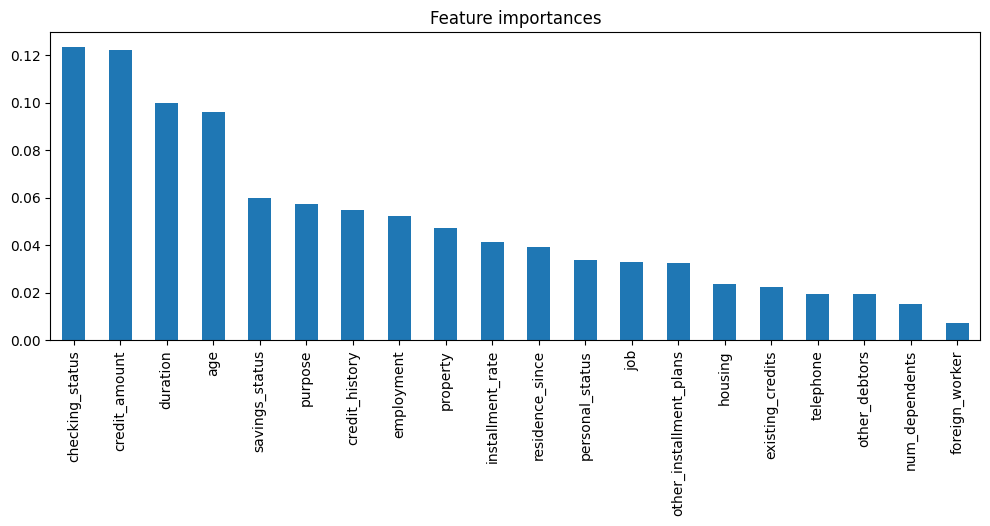

In [56]:
import pandas as pd

importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances.sort_values(ascending=False).plot(kind='bar', figsize=(12,4), title='Feature importances')

# 2) Generate DiCE counterfactuals

## install DiCE

In [57]:
pip install dice-ml

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## set up DiCE data and model objects

In [58]:
import dice_ml
import pandas as pd

# DiCE needs training data with target included
train_df = X_train.copy()
train_df['target'] = y_train.values

d = dice_ml.Data(
    dataframe=train_df,
    continuous_features=['duration', 'credit_amount', 'installment_rate',
                         'residence_since', 'age', 'existing_credits', 'num_dependents'],
    outcome_name='target'
)

m = dice_ml.Model(model=rf_model, backend='sklearn')
exp = dice_ml.Dice(d, m, method='genetic')
print("DiCE ready.")

DiCE ready.


## pick a rejected applicant and generate CFs

In [59]:
X_test_df = X_test.copy()
X_test_df['target'] = y_test.values
rejected = X_test_df[X_test_df['target'] == 2].drop('target', axis=1)
print(f"Rejected applicants in test set: {len(rejected)}")

query_instance = rejected.iloc[[0]]
print("\nOriginal rejected applicant:")
print(query_instance.T)

Rejected applicants in test set: 60

Original rejected applicant:
                          289
checking_status             0
duration                   24
credit_history              3
purpose                     4
credit_amount            1024
savings_status              0
employment                  1
installment_rate            4
personal_status             3
other_debtors               0
residence_since             4
property                    0
age                        48
other_installment_plans     1
housing                     1
existing_credits            1
job                         2
num_dependents              1
telephone                   0
foreign_worker              0


In [60]:
print("Unique target values:", train_df['target'].unique())
print("Desired class should be: 1 (good)")

Unique target values: [2 1]
Desired class should be: 1 (good)


## generate counterfactuals

In [61]:
cf = exp.generate_counterfactuals(
    query_instance,
    total_CFs=5,
    desired_class="opposite",   # flip whatever the current prediction is
    features_to_vary=['checking_status', 'duration', 'credit_history',
                      'credit_amount', 'savings_status', 'employment',
                      'installment_rate', 'other_debtors', 'residence_since',
                      'property', 'other_installment_plans', 'housing',
                      'existing_credits', 'job', 'telephone']
)

# get CF dataframe
cf_df = cf.cf_examples_list[0].final_cfs_df.copy()

# decode categorical columns back to original codes
for col, le in label_encoders.items():
    if col in cf_df.columns:
        cf_df[col] = le.inverse_transform(cf_df[col].astype(int))

# decode original query too
query_decoded = query_instance.copy()
for col, le in label_encoders.items():
    if col in query_decoded.columns:
        query_decoded[col] = le.inverse_transform(query_decoded[col].astype(int))

print("Original applicant (decoded):")
print(query_decoded.T)
print("\nCounterfactuals (decoded):")
print(cf_df.T)

100%|██████████| 1/1 [00:02<00:00,  2.18s/it]

Original applicant (decoded):
                          289
checking_status           A11
duration                   24
credit_history            A33
purpose                   A43
credit_amount            1024
savings_status            A61
employment                A72
installment_rate            4
personal_status           A94
other_debtors            A101
residence_since             4
property                 A121
age                        48
other_installment_plans  A142
housing                  A152
existing_credits            1
job                      A173
num_dependents              1
telephone                A191
foreign_worker           A201

Counterfactuals (decoded):
                            0     0     0     0     0
checking_status           A12   A12   A11   A11   A11
duration                   10     9     4     4     4
credit_history            A31   A32   A32   A31   A32
purpose                   A43   A43   A43   A43   A43
credit_amount            1048  1206   276 

# Define compute_metrics

In [78]:
import time
import numpy as np

immutable_features = ['age', 'personal_status', 'num_dependents', 'foreign_worker']
numeric_features   = ['duration', 'credit_amount', 'installment_rate',
                      'residence_since', 'age', 'existing_credits', 'num_dependents']
direction_map = {
    'duration':        'decrease',
    'credit_amount':   'decrease',
    'installment_rate':'decrease',
    'existing_credits':'decrease',
    'credit_history':  'increase',
    'savings_status':  'increase',
    'employment':      'increase',
    'residence_since': 'increase',
    'property':        'increase',
    'job':             'increase',
}

def compute_metrics(original_row, cf_row, immutable_features,
                    numeric_features, direction_map, gen_time):

    # sparsity — count changed features
    sparsity = sum(
        1 for col in original_row.index
        if col not in ['target', 'instance_id']
        and str(original_row[col]) != str(cf_row[col])
    )

    # proximity — L1 distance on numeric features
    proximity = sum(
        abs(float(original_row[col]) - float(cf_row[col]))
        for col in numeric_features
        if col in original_row.index and col in cf_row.index
    ) / len(numeric_features)

    # immutable violations
    immut_viol = sum(
        1 for col in immutable_features
        if col in original_row.index and col in cf_row.index
        and str(original_row[col]) != str(cf_row[col])
    )

    # direction violations
    dir_viol = 0
    for col, direction in direction_map.items():
        if col not in original_row.index or col not in cf_row.index:
            continue
        orig_val = original_row[col]
        cf_val   = cf_row[col]
        if orig_val == cf_val:
            continue
        try:
            if direction == 'increase' and float(cf_val) < float(orig_val):
                dir_viol += 1
            elif direction == 'decrease' and float(cf_val) > float(orig_val):
                dir_viol += 1
        except:
            pass

    return {
        'sparsity_score':        sparsity,
        'proximity_score':       round(proximity, 4),
        'immutable_violations':  immut_viol,
        'direction_violations':  dir_viol,
        'generation_time':       round(gen_time, 4),
    }

print("Metrics function defined.")

Metrics function defined.


# Compute metrics for all CF

In [79]:
# compute metrics for all 5 CFs
original_series = query_decoded.iloc[0].copy()
original_series['target'] = 2

start_time = time.time()
metrics_list = []
cf_reset = cf_df.reset_index(drop=True)

for i, row in cf_reset.iterrows():
    gen_time = time.time() - start_time
    m = compute_metrics(
        original_series, row,
        immutable_features, numeric_features,
        direction_map, gen_time
    )
    metrics_list.append(m)
    print(f"CF {i+1}: sparsity={m['sparsity_score']} "
          f"proximity={m['proximity_score']} "
          f"immut_viol={m['immutable_violations']} "
          f"dir_viol={m['direction_violations']}")

print("\nAll metrics computed.")

CF 1: sparsity=6 proximity=5.4286 immut_viol=0 dir_viol=1
CF 2: sparsity=6 proximity=28.1429 immut_viol=0 dir_viol=1
CF 3: sparsity=6 proximity=109.7143 immut_viol=0 dir_viol=0
CF 4: sparsity=7 proximity=109.7143 immut_viol=0 dir_viol=0
CF 5: sparsity=7 proximity=109.7143 immut_viol=0 dir_viol=0

All metrics computed.


# Save CSV with metrics

In [80]:
# add metrics to CF CSV and resave
rml_dir = r"C:\TEST\KG\rml"

cf_csv = cf_df.reset_index(drop=True).copy()
cf_csv['instance_id']           = [f'cf_{i+1}_289' for i in range(len(cf_csv))]
cf_csv['approval_probability']  = [round(float(p), 4) for p in probs]
cf_csv['method']                = 'DiCE'
cf_csv['model_type']            = 'RandomForest'
cf_csv['dataset_name']          = 'GermanCredit'
cf_csv['cf_index']              = [i+1 for i in range(len(cf_csv))]
cf_csv['sparsity_score']        = [m['sparsity_score']       for m in metrics_list]
cf_csv['proximity_score']       = [m['proximity_score']      for m in metrics_list]
cf_csv['immutable_violations']  = [m['immutable_violations'] for m in metrics_list]
cf_csv['direction_violations']  = [m['direction_violations'] for m in metrics_list]
cf_csv['generation_time']       = [m['generation_time']      for m in metrics_list]

cf_csv.to_csv(f"{rml_dir}\\counterfactuals.csv", index=False)
print("CSV saved with metrics.")
print(cf_csv[['instance_id', 'sparsity_score', 'proximity_score',
              'immutable_violations', 'direction_violations']].to_string())

CSV saved with metrics.
  instance_id  sparsity_score  proximity_score  immutable_violations  direction_violations
0    cf_1_289               6           5.4286                     0                     1
1    cf_2_289               6          28.1429                     0                     1
2    cf_3_289               6         109.7143                     0                     0
3    cf_4_289               7         109.7143                     0                     0
4    cf_5_289               7         109.7143                     0                     0


In [62]:
pip install jinja2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Display Cfs as table

In [63]:
code_map = {
    'checking_status': {
        'A11': 'Overdrawn account',
        'A12': 'Low balance (0–200 DM)',
        'A13': 'Healthy balance (200+ DM)',
        'A14': 'No overdraft account'
    },
    'credit_history': {
        'A30': 'No credits taken / all paid back',
        'A31': 'All credits at this bank paid back',
        'A32': 'Existing credits paid back duly',
        'A33': 'Delay in paying off in the past',
        'A34': 'Critical account / other credits existing'
    },
    'savings_status': {
        'A61': 'Savings < 100 DM',
        'A62': 'Savings 100–500 DM',
        'A63': 'Savings 500–1000 DM',
        'A64': 'Savings >= 1000 DM',
        'A65': 'No savings account'
    },
    'employment': {
        'A71': 'Unemployed',
        'A72': 'Employed < 1 year',
        'A73': 'Employed 1–4 years',
        'A74': 'Employed 4–7 years',
        'A75': 'Employed 7+ years'
    },
    'other_debtors': {
        'A101': 'No other debtors',
        'A102': 'Co-applicant',
        'A103': 'Has guarantor'
    },
    'property': {
        'A121': 'Owns real estate',
        'A122': 'Has life insurance',
        'A123': 'Owns a car',
        'A124': 'No property'
    },
    'other_installment_plans': {
        'A141': 'Installment plan at bank',
        'A142': 'Installment plan at stores',
        'A143': 'No other installment plans'
    },
    'housing': {
        'A151': 'Renting',
        'A152': 'Owns home',
        'A153': 'Housing for free'
    },
    'job': {
        'A171': 'Unemployed / unskilled non-resident',
        'A172': 'Unskilled resident',
        'A173': 'Skilled employee',
        'A174': 'Management / highly qualified'
    },
    'telephone': {
        'A191': 'No registered phone',
        'A192': 'Has registered phone'
    },
    'personal_status': {
        'A91': 'Male: divorced/separated',
        'A92': 'Female: divorced/separated/married',
        'A93': 'Male: single',
        'A94': 'Male: married/widowed',
        'A95': 'Female: single'
    },
    'purpose': {
        'A40': 'New car',
        'A41': 'Used car',
        'A42': 'Furniture / equipment',
        'A43': 'Radio / television',
        'A44': 'Domestic appliances',
        'A45': 'Repairs',
        'A46': 'Education',
        'A48': 'Retraining',
        'A49': 'Business',
        'A410': 'Other'
    },
    'foreign_worker': {
        'A201': 'Foreign worker: yes',
        'A202': 'Foreign worker: no'
    },
    'target': {
        1: 'Approved', 2: 'Rejected',
        1.0: 'Approved', 2.0: 'Rejected'
    }
}

col_rename = {
    'checking_status':         'Checking Account',
    'duration':                'Loan Duration (months)',
    'credit_history':          'Credit History',
    'credit_amount':           'Credit Amount (DM)',
    'savings_status':          'Savings Status',
    'employment':              'Employment Duration',
    'installment_rate':        'Installment Rate (%)',
    'other_debtors':           'Other Debtors',
    'residence_since':         'Years at Residence',
    'property':                'Property Owned',
    'other_installment_plans': 'Other Installment Plans',
    'housing':                 'Housing Status',
    'existing_credits':        'Existing Credits',
    'job':                     'Job Type',
    'telephone':               'Phone Registration',
    'personal_status':         'Personal Status',
    'purpose':                 'Loan Purpose',
    'foreign_worker':          'Foreign Worker',
    'target':                  'Decision'
}

original_row = query_decoded.copy()
original_row['target'] = 2
original_row['type'] = 'Original (Rejected)'

cf_display = cf_df.copy()
cf_display['type'] = [f'CF {i+1} (Approved)' for i in range(len(cf_df))]

combined = pd.concat([original_row, cf_display], ignore_index=True)
combined = combined.set_index('type')

changed_cols = [col for col in cf_df.columns
                if col != 'target' and
                (cf_df[col] != query_decoded.iloc[0][col]).any()]

display_df = combined[changed_cols + ['target']].copy()

for col, mapping in code_map.items():
    if col in display_df.columns:
        display_df[col] = display_df[col].map(lambda x: mapping.get(x, mapping.get(str(x), x)))

display_df = display_df.rename(columns=col_rename)
display_df.index.name = None

def highlight_changes(col):
    if col.name == 'Decision':
        return ['' for _ in col]
    original_val = display_df.loc['Original (Rejected)', col.name]
    styles = []
    for idx, v in col.items():
        if idx == 'Original (Rejected)':
            styles.append('background-color: #8B0000; color: white')
        elif v != original_val:
            styles.append('background-color: #B8860B; color: white')
        else:
            styles.append('background-color: #2F2F2F; color: white')
    return styles

styled = display_df.style\
    .apply(highlight_changes)\
    .set_caption("What would get this applicant approved? (golden cells = suggested changes)")\
    .set_properties(**{'text-align': 'center', 'border': '1px solid #555', 'padding': '10px', 'font-size': '13px'})\
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold'),
                                          ('padding', '12px'), ('color', 'white'),
                                          ('background-color', '#1a1a1a')]},
        {'selector': 'th', 'props': [('background-color', '#00008B'), ('color', 'white'),
                                     ('padding', '10px'), ('font-size', '13px')]},
    ])

styled

,Checking Account,Loan Duration (months),Credit History,Credit Amount (DM),Employment Duration,Property Owned,Other Installment Plans,Job Type,Decision
Original (Rejected),Overdrawn account,24,Delay in paying off in the past,1024,Employed < 1 year,Owns real estate,Installment plan at stores,Skilled employee,Rejected
CF 1 (Approved),Low balance (0–200 DM),10,All credits at this bank paid back,1048,Employed 1–4 years,Owns real estate,Installment plan at stores,Unskilled resident,Approved
CF 2 (Approved),Low balance (0–200 DM),9,Existing credits paid back duly,1206,Employed 7+ years,Owns real estate,No other installment plans,Skilled employee,Approved
CF 3 (Approved),Overdrawn account,4,Existing credits paid back duly,276,Employed 4–7 years,Has life insurance,Installment plan at bank,Skilled employee,Approved
CF 4 (Approved),Overdrawn account,4,All credits at this bank paid back,276,Employed 7+ years,Has life insurance,Installment plan at bank,Unemployed / unskilled non-resident,Approved
CF 5 (Approved),Overdrawn account,4,Existing credits paid back duly,276,Employed 7+ years,Has life insurance,Installment plan at bank,Unemployed / unskilled non-resident,Approved


# 3) RDF conversion using ontology.ttl

## imports and installs 

In [64]:
!pip install morph-kgc


[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: C:\Users\Ashwi\miniconda3\python.exe -m pip install --upgrade pip


In [82]:
import morph_kgc
from rdflib import Graph, URIRef, Literal, RDF, OWL
from rdflib.namespace import RDFS, XSD
import pandas as pd
import os

print("All imports done.")

All imports done.


## Save CSVs for RML

In [89]:
rml_dir = r"C:\TEST\KG\rml"
os.makedirs(rml_dir, exist_ok=True)

# original applicant
original_csv = query_decoded.copy()
original_csv['target'] = 2
original_csv['instance_id'] = 'original_289'
original_csv.to_csv(os.path.join(rml_dir, "original.csv"), index=False)

# CFs — with all metrics included
cf_csv = cf_df.reset_index(drop=True).copy()
cf_csv['instance_id']           = [f'cf_{i+1}_289' for i in range(len(cf_csv))]
cf_csv['approval_probability']  = [round(float(p), 4) for p in probs]
cf_csv['method']                = 'DiCE'
cf_csv['model_type']            = 'RandomForest'
cf_csv['dataset_name']          = 'GermanCredit'
cf_csv['cf_index']              = [i+1 for i in range(len(cf_csv))]
cf_csv['sparsity_score']        = [m['sparsity_score']       for m in metrics_list]
cf_csv['proximity_score']       = [m['proximity_score']      for m in metrics_list]
cf_csv['immutable_violations']  = [m['immutable_violations'] for m in metrics_list]
cf_csv['direction_violations']  = [m['direction_violations'] for m in metrics_list]
cf_csv['generation_time']       = [m['generation_time']      for m in metrics_list]

cf_csv.to_csv(os.path.join(rml_dir, "counterfactuals.csv"), index=False)

print("Saved:")
print(f"  {rml_dir}\\original.csv")
print(f"  {rml_dir}\\counterfactuals.csv")
print(f"\nTotal columns: {len(cf_csv.columns)}")
print("\nCF CSV preview:")
print(cf_csv[['instance_id', 'cf_index', 'approval_probability',
              'sparsity_score', 'proximity_score',
              'immutable_violations', 'direction_violations',
              'generation_time']].to_string())

Saved:
  C:\TEST\KG\rml\original.csv
  C:\TEST\KG\rml\counterfactuals.csv

Total columns: 32

CF CSV preview:
  instance_id  cf_index  approval_probability  sparsity_score  proximity_score  immutable_violations  direction_violations  generation_time
0    cf_1_289         1                0.6200               6           5.4286                     0                     1           0.0018
1    cf_2_289         2                0.5633               6          28.1429                     0                     1           0.0034
2    cf_3_289         3                0.7433               6         109.7143                     0                     0           0.0047
3    cf_4_289         4                0.7800               7         109.7143                     0                     0           0.0053
4    cf_5_289         5                0.9233               7         109.7143                     0                     0           0.0061


## Run morph-kgc

In [90]:
g = morph_kgc.materialize(r"C:\TEST\KG\rml\config.ini")
print(f"Triples generated by RML: {len(g)}")

INFO | 2026-06-20 21:52:40,911 | Parallelization is not supported for win32 when running as a library. If you need to speed up your data integration pipeline, please run through the command line.


INFO | 2026-06-20 21:52:42,142 | 57 mapping rules retrieved.
INFO | 2026-06-20 21:52:42,170 | Mapping partition with 35 groups generated.
INFO | 2026-06-20 21:52:42,172 | Maximum number of rules within mapping group: 2.
INFO | 2026-06-20 21:52:42,173 | Mappings processed in 1.256 seconds.
INFO | 2026-06-20 21:52:42,595 | Number of triples generated in total: 197.


Triples generated by RML: 197


## Add named individuals and save

In [91]:
EX = "http://example.org/credit#"

# add DiCE as named individual
g.add((URIRef(f"{EX}DiCE"), RDF.type,    OWL.NamedIndividual))
g.add((URIRef(f"{EX}DiCE"), RDFS.label,  Literal("DiCE")))
g.add((URIRef(f"{EX}DiCE"), RDFS.comment,Literal("Diverse Counterfactual Explanations — Microsoft Research.")))

print(f"Triples after adding named individuals: {len(g)}")

# save
rdf_path = r"C:\TEST\KG\rml\output_rml.ttl"
g.serialize(destination=rdf_path, format="turtle")
print(f"Saved: {rdf_path}")

# preview
with open(rdf_path, "r") as f:
    lines = f.readlines()
for line in lines[:35]:
    print(line, end="")

Triples after adding named individuals: 200
Saved: C:\TEST\KG\rml\output_rml.ttl
@prefix ns1: <http://example.org/credit#> .
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

<http://example.org/credit/applicant/cf_1_289> a ns1:CreditApplicant ;
    ns1:age 48 ;
    ns1:checkingAccountStatus "A12" ;
    ns1:creditAmount 1048.0 ;
    ns1:creditHistory "A31" ;
    ns1:creditRisk 1 ;
    ns1:duration 10 ;
    ns1:employmentSince "A73" ;
    ns1:existingCredits 1 ;
    ns1:foreignWorker "A201" ;
    ns1:housingStatus "A152" ;
    ns1:installmentRate 4 ;
    ns1:isCounterfactualOf <http://example.org/credit/applicant/original_289> ;
    ns1:jobType "A172" ;
    ns1:loanPurpose "A43" ;
    ns1:numberOfDependents 1 ;
    ns1:otherDebtors "A101" ;
    ns1:otherInstallmentPlans "A142" ;
    ns1:personalStatus "A94" ;
    ns1:propertyType "A121" ;
    ns1:residenceSince 4 ;
    ns1:savingsSt

In [92]:
from rdflib import Graph
g = Graph()
g.parse(r"C:\TEST\KG\ontology.ttl", format="turtle")
print(f"Ontology triples: {len(g)}")

Ontology triples: 179


## Display RDF graph

In [93]:
pip install networkx matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


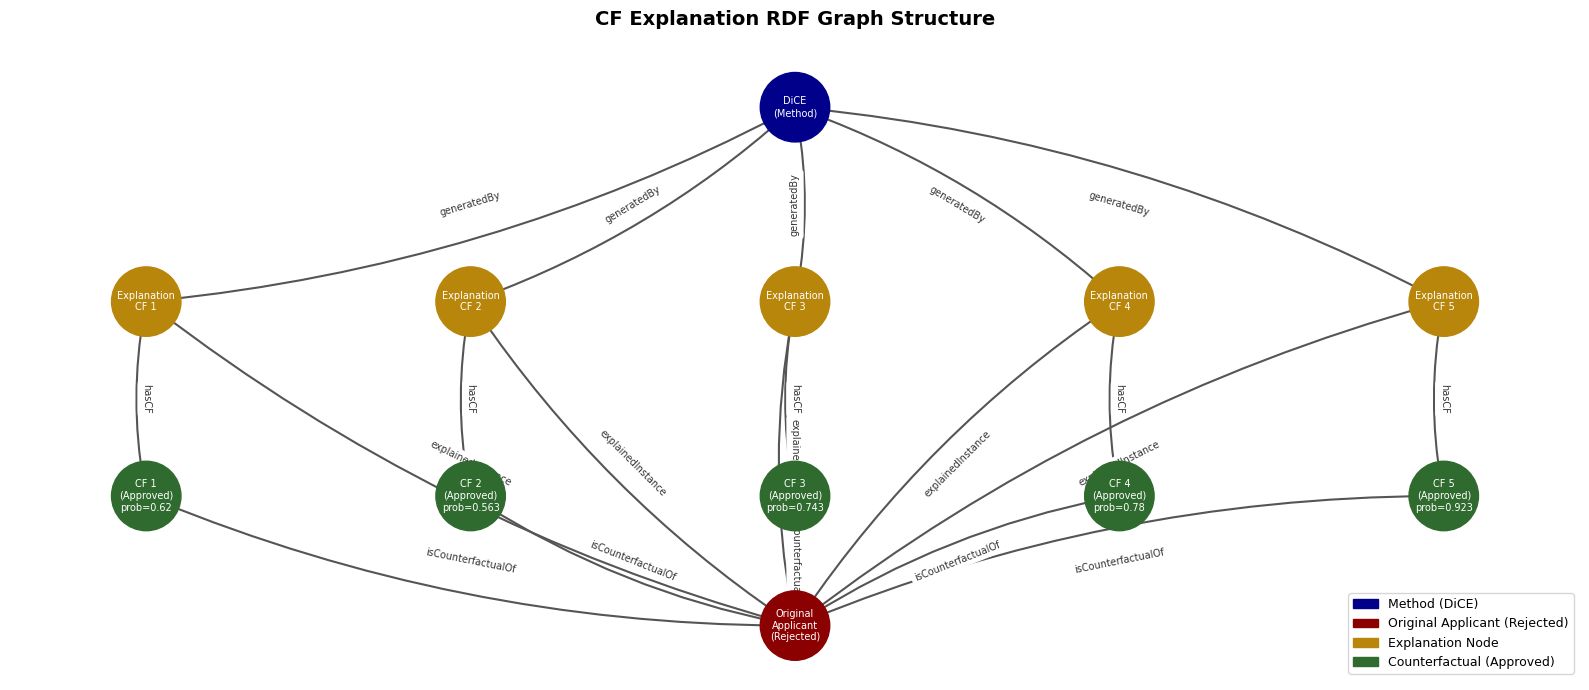

Graph saved to C:\TEST\KG\rdf\cf_graph.png


In [94]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ensure probs is available
try:
    probs
except NameError:
    cf_features = cf_df.drop('target', axis=1).copy()
    for col, le in label_encoders.items():
        if col in cf_features.columns:
            cf_features[col] = le.transform(cf_features[col].astype(str))
    probs = rf_model.predict_proba(cf_features)[:, 0]
    print("Probs recomputed.")

# build graph of just the CF explanation structure
G = nx.DiGraph()

# node labels
nodes = {
    'DiCE': 'DiCE\n(Method)',
    'original': 'Original\nApplicant\n(Rejected)',
}
for i in range(1, 6):
    nodes[f'cf_{i}'] = f'CF {i}\n(Approved)\nprob={round(probs[i-1], 3)}'
    nodes[f'exp_{i}'] = f'Explanation\nCF {i}'

for node, label in nodes.items():
    G.add_node(node, label=label)

# edges
for i in range(1, 6):
    G.add_edge(f'exp_{i}', 'DiCE',       label='generatedBy')
    G.add_edge(f'exp_{i}', 'original',   label='explainedInstance')
    G.add_edge(f'cf_{i}',  'original',   label='isCounterfactualOf')
    G.add_edge(f'exp_{i}', f'cf_{i}',    label='hasCF')

# layout
pos = {
    'DiCE':     (4, 4),
    'original': (4, 0),
}
for i in range(1, 6):
    pos[f'exp_{i}'] = (i * 1.5 - 0.5, 2.5)
    pos[f'cf_{i}']  = (i * 1.5 - 0.5, 1.0)

# colors by node type
color_map = []
for node in G.nodes():
    if node == 'DiCE':
        color_map.append('#00008B')
    elif node == 'original':
        color_map.append('#8B0000')
    elif node.startswith('exp_'):
        color_map.append('#B8860B')
    else:
        color_map.append('#2F6A2F')

fig, ax = plt.subplots(figsize=(16, 7))
labels = nx.get_node_attributes(G, 'label')
edge_labels = nx.get_edge_attributes(G, 'label')

nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=2500, ax=ax)
nx.draw_networkx_labels(G, pos, labels=labels, font_color='white', font_size=7, ax=ax)
nx.draw_networkx_edges(G, pos, edge_color='#555555', arrows=True,
                       arrowsize=20, width=1.5,
                       connectionstyle='arc3,rad=0.1', ax=ax)
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels,
                              font_size=7, font_color='#333333', ax=ax)

legend = [
    mpatches.Patch(color='#00008B', label='Method (DiCE)'),
    mpatches.Patch(color='#8B0000', label='Original Applicant (Rejected)'),
    mpatches.Patch(color='#B8860B', label='Explanation Node'),
    mpatches.Patch(color='#2F6A2F', label='Counterfactual (Approved)'),
]
ax.legend(handles=legend, loc='lower right', fontsize=9)
ax.set_title('CF Explanation RDF Graph Structure', fontsize=14, fontweight='bold', pad=20)
ax.axis('off')
plt.tight_layout()
plt.savefig(r"C:\TEST\KG\rdf\cf_graph.png", dpi=150, bbox_inches='tight')
plt.show()
print("Graph saved to C:\\TEST\\KG\\rdf\\cf_graph.png")

# 4) pySHACL validation against shapes.ttl

## install pySHACL

In [95]:
pip install pyshacl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## validate CF RDF graph against SHACL shapes


In [98]:
from pyshacl import validate
from rdflib import Graph

data_graph = Graph()
data_graph.parse(r"C:\TEST\KG\rml\output_rml.ttl", format="turtle")

# load all shape files together
shapes_graph = Graph()
shapes_graph.parse(r"C:\TEST\KG\shapes.ttl",                format="turtle")
shapes_graph.parse(r"C:\TEST\KG\shapes_cf.ttl",             format="turtle")
shapes_graph.parse(r"C:\TEST\KG\shapes_immutability.ttl",   format="turtle")
shapes_graph.parse(r"C:\TEST\KG\shapes_cf_universal.ttl",   format="turtle")

conforms, results_graph, results_text = validate(
    data_graph,
    shacl_graph=shapes_graph,
    inference='rdfs',
    abort_on_first=False,
    debug=False
)

print(f"Conforms: {conforms}")
print(results_text)

Conforms: False
Validation Report
Conforms: False
Results (2):
Constraint Violation in MaxInclusiveConstraintComponent (http://www.w3.org/ns/shacl#MaxInclusiveConstraintComponent):
	Severity: sh:Violation
	Source Shape: [ sh:datatype xsd:integer ; sh:description Literal("Number of features changed in wrong direction. Must be 0 for valid recourse.") ; sh:maxInclusive Literal("0", datatype=xsd:integer) ; sh:message Literal("CF violated one or more feature direction constraints. This CF is not valid recourse.") ; sh:minInclusive Literal("0", datatype=xsd:integer) ; sh:name Literal("directionViolations") ; sh:order Literal("2", datatype=xsd:integer) ; sh:path ex:directionViolations ]
	Focus Node: <http://example.org/credit/explanation/cf_1_289>
	Value Node: Literal("1", datatype=xsd:integer)
	Result Path: ex:directionViolations
	Message: CF violated one or more feature direction constraints. This CF is not valid recourse.
Constraint Violation in MaxInclusiveConstraintComponent (http://www.

In [1]:
from rdflib import Graph

g = Graph()
g.parse(r"C:\TEST\KG\shapes_coherence.ttl", format="turtle")
print(f"Coherence shape triples: {len(g)}")

Coherence shape triples: 37


In [2]:
from pyshacl import validate
from rdflib import Graph

data_graph = Graph()
data_graph.parse(r"C:\TEST\KG\rml\output_rml.ttl", format="turtle")

shapes_graph = Graph()
shapes_graph.parse(r"C:\TEST\KG\shapes_coherence.ttl", format="turtle")

conforms, results_graph, results_text = validate(
    data_graph,
    shacl_graph=shapes_graph,
    inference='rdfs',
    abort_on_first=False,
    debug=False
)

print(f"Conforms: {conforms}")
print(results_text)

Conforms: False
Validation Report
Conforms: False
Results (7):
Constraint Violation in SPARQLConstraintComponent (http://www.w3.org/ns/shacl#SPARQLConstraintComponent):
	Severity: sh:Violation
	Source Shape: ex:CoherenceShape
	Focus Node: <http://example.org/credit/applicant/cf_2_289>
	Value Node: <http://example.org/credit/applicant/cf_2_289>
	Source Constraint: [ sh:description Literal("Employment cannot jump more than 2 tiers in one CF.") ; sh:message Literal("Coherence violation: employment jumped more than 2 tiers. Not realistic in one step.") ; sh:name Literal("employmentJumpLimit") ; sh:prefixes <http://example.org/credit#> ; sh:select Literal("
            PREFIX ex: <http://example.org/credit#>
            SELECT $this ?cfEmp ?origEmp
            WHERE {
                $this ex:isCounterfactualOf ?original .
                $this ex:employmentSince ?cfEmp .
                ?original ex:employmentSince ?origEmp .
                FILTER (
                    (?origEmp = "A71" &

In [3]:
from pyshacl import validate
from rdflib import Graph

data_graph = Graph()
data_graph.parse(r"C:\TEST\KG\rml\output_rml.ttl", format="turtle")

shapes_graph = Graph()
shapes_graph.parse(r"C:\TEST\KG\shapes.ttl",                format="turtle")
shapes_graph.parse(r"C:\TEST\KG\shapes_cf.ttl",             format="turtle")
shapes_graph.parse(r"C:\TEST\KG\shapes_immutability.ttl",   format="turtle")
shapes_graph.parse(r"C:\TEST\KG\shapes_cf_universal.ttl",   format="turtle")
shapes_graph.parse(r"C:\TEST\KG\shapes_coherence.ttl",      format="turtle")

conforms, results_graph, results_text = validate(
    data_graph,
    shacl_graph=shapes_graph,
    inference='rdfs',
    abort_on_first=False,
    debug=False
)

print(f"Conforms: {conforms}")
print(results_text)

Conforms: False
Validation Report
Conforms: False
Results (9):
Constraint Violation in MaxInclusiveConstraintComponent (http://www.w3.org/ns/shacl#MaxInclusiveConstraintComponent):
	Severity: sh:Violation
	Source Shape: [ sh:datatype xsd:integer ; sh:description Literal("Number of features changed in wrong direction. Must be 0 for valid recourse.") ; sh:maxInclusive Literal("0", datatype=xsd:integer) ; sh:message Literal("CF violated one or more feature direction constraints. This CF is not valid recourse.") ; sh:minInclusive Literal("0", datatype=xsd:integer) ; sh:name Literal("directionViolations") ; sh:order Literal("2", datatype=xsd:integer) ; sh:path ex:directionViolations ]
	Focus Node: <http://example.org/credit/explanation/cf_1_289>
	Value Node: Literal("1", datatype=xsd:integer)
	Result Path: ex:directionViolations
	Message: CF violated one or more feature direction constraints. This CF is not valid recourse.
Constraint Violation in MaxInclusiveConstraintComponent (http://www.